# Tutorial 01 — Predict thermal power demand with a 5R1C model

This notebook shows the **prediction path** for the 5R1C thermal model: how to take a calibrated 7-parameter vector (produced by the GA identification pipeline) and use it to forecast heat pump thermal power demand on a user-chosen time window.

**The 5R1C model** serves as a proxy for the heat pump actuation channel, providing a mapping between the available control: thermostat setpoint $T_{set}$, and heat power output $\Phi_{HC}$. It achieves this, by modeling a thermal dynamics of the building with a thermal network of 5 resistances and 1 thermal mass capacitance (EN ISO 13790:2008). 

It takes as inputs: 
- Disturbances: outdoor temperature $T_a$ and solar irradiance: $Phi_{sol}$, and 
- Control: thermostat setpoint $T_{set}$.

Its output is the heat pump power $\Phi_{HC}$, required to track that setpoint, derived by linear interpolation between two power probes — the so-called *demand-via-probing* trick.

Seven free parameters are identified per building by the calibration pipeline (`A_f`, `H_em`, `H_w`, `H_ve`, `c_f`, `phi_int_f`, `k_sol`); here we just *load* them.



**What this notebook covers.**
1. Build a `FiveR1C_ENISO13790` model directly from a calibrated `results.json`
2. Slice the raw HEMS DataFrame into flexible time windows.
3. Push those windows through `NumpyDataLoader` to produce a batched tensor dict.
4. Predict + evaluate with `predict_for_batch_and_evaluate` and `predict_for_batch`.
5. Plot predicted vs. measured power for one window.

**Concrete example.** AIBF (Žalec, air-to-water 12 kW, radiators) calibrated on December 2023. We predict on the unseen `w2526` winter (Sept 2025 – Apr 2026).

## 1. Imports + paths

Two paths are configurable: `RESULTS_PATH` points at the calibration artefact (`results.json`) and `DATA_PATH` points at the prepared HEMS pickle for the same building. Swap these to retarget the notebook to a different building or calibration run.

In [1]:
import json
import os
from pathlib import Path
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rctoolbox.models.rc.five_r1c_eniso13790.model import FiveR1C_ENISO13790
from rctoolbox.data.time_windows_generator import generate_time_windows
from rctoolbox.data.numpydataloader import DataLoader
from rctoolbox.utils.project_root import find_project_root

project_root = find_project_root()
os.chdir(project_root)
# print(f"Current working directory: {os.getcwd()}")

In [2]:
HEMS_ID = "AIBF"

IDENT_DIRECTORY_PATH = project_root / "examples" / "run_identification" / "five_r1c_eniso13790" / HEMS_ID
RESULTS_DIR_PATH = IDENT_DIRECTORY_PATH / "results"
RESULTS_JSON_PATH = RESULTS_DIR_PATH / "results.json"

DATA_DIR  = project_root / "examples" / "data"
DATA_PATH = DATA_DIR / 'AIBF_data.pkl'
SEASON    = 'w2425'

# print('results:', RESULTS_JSON_PATH.exists(), RESULTS_JSON_PATH)
# print('data:   ', DATA_PATH.exists(), DATA_PATH)

## 2. Construct the calibrated model from `results.json`

We do this **manually** rather than calling `rctoolbox.models.rc.five_r1c_eniso13790.load_best_5r1c` so the moving parts are visible. The four-step recipe is:

1. **Read `results.json`** — the calibration pipeline writes this file. It holds 
- `setup.building_config` (the building metadata used at calibration time), 
- `setup.config.model_config.init_config` (how to initialize the model state), and 
- `results.best_candidate.params` (the overall-best 7 RC parameters across the GA history). 

Per-cluster best candidates also live under `results.clustering-results.<cluster_id>.best_candidate.params`.

2. **Instantiate `FiveR1C_ENISO13790()`** — empty model, no parameters yet.

3. **`set_heat_power_range([0, max_HP_power])`** — bounds imposed during power demand calculation.

4. **`set_initialization(init_config=...)`** — picks the regime that turns the lag window into an initial state `(T_m, T_s, T_i)` at the start of each forecast (`regime_aware`, `steady_state`, `dynamic`).

5. **`set_params(params)`** — fixes the 7 free RC parameters.

This is exactly what `load_best_5r1c(RESULTS_PATH, best_from_cluster=False)` does in one line, but unrolled.

In [3]:
with open(RESULTS_JSON_PATH, 'r') as f:
    results = json.load(f)
results

{'setup': {'building_config': {'hems_id': 'AIBF',
   'max_HP_power': 12000,
   'JPD': {'A_f': 117.6, 'n_floors': 2},
   'exact_A_f_bounds': None},
  'seed': 23,
  'identification_config': {'model_config': {'model_type': '5R1C_heat_demand',
    'init_config': {'method': 'regime_aware', 'variant': 'last'}},
   'optimization_config': {'objective_function': 'MAE',
    'std_weight': 0.0,
    'pop_size': 100,
    'n_gen': 150},
   'selection_config': {'criteria': 'val error',
    'select_R_star': True,
    'threshold_config': {'type': 'idx', 'x': 12000}},
   'clustering_config': {'min_samples_ratio': 0.1,
    'cl_eval_metric': 'MAE',
    'cl_eval_criteria': 'val error'}}},
 'results': {'best_candidate': {'params': {'A_f': 117.67398,
    'H_em': 343.63809,
    'H_w': 107.20463,
    'H_ve': 13.61815,
    'c_f': 259478.38748,
    'phi_int_f': 3.22789,
    'k_sol': 2.15124},
   'train_error': 521.13335,
   'validation_error': 522.11272,
   'criteria': 522.11272},
  'clustering-results': {'0': {'

Identification pipeline use genetic algorithm and outputs space or pool of good quality solutions: $R^*$. This this space is then explored with clustering, in order to detect unique solutions. 

In [4]:
# from rctoolbox.models.rc.five_r1c_eniso13790.loader import get_best_candidates_2
# dfr, _ = get_best_candidates_2(RESULTS_DIR_PATH)
# dfr

In [5]:
max_hp_power = results['setup']['building_config']['max_HP_power']
init_config  = results['setup']['identification_config']['model_config']['init_config']
params       = results['results']['best_candidate']['params']


# # Uncomment the following lines to use the best candidate from a specific cluster instead of the overall best candidate
# cluster_id = '0'
# params = results['results']['clustering-results'][cluster_id]['best_candidate']['params']
# model.set_params(params)

model = FiveR1C_ENISO13790()
model.set_heat_power_range([0, max_hp_power])
model.set_initialization(init_config=init_config)
model.set_params(params)

print('max_HP_power:', max_hp_power, 'W')
print('init_config: ', init_config)
print('calibrated parameters:')
for k, v in params.items():
    print(f'  {k:>10} = {v}')

max_HP_power: 12000 W
init_config:  {'method': 'regime_aware', 'variant': 'last'}
calibrated parameters:
         A_f = 117.67398
        H_em = 343.63809
         H_w = 107.20463
        H_ve = 13.61815
         c_f = 259478.38748
   phi_int_f = 3.22789
       k_sol = 2.15124


## 3. Load the data

`AIBF_data.pkl` is a dict keyed by winter season. Each season contains an hourly DataFrame `df`. 

Columns the 5R1C uses:
- `T_a` — outdoor temperature [°C]
- `Phi_sol` — solar gains [W]
- `y1` — measured indoor temperature [°C] (used to seed `T_i_0`)
- `y1_set` — thermostat setpoint
- `Phi_HC` — measured heat pump electrical power [W] (the target)
- `missing_flag`, `control_day` — mask columns honoured by the prediction utilities

In [6]:
DATA = pd.read_pickle(DATA_PATH)
season = DATA[SEASON]
df = season['df']

print('season:        ', SEASON)
print('df shape:      ', df.shape)
print('time range:    ', df.index.min(), '->', df.index.max())

DATA.keys()

season:         w2425
df shape:       (3697, 10)
time range:     2024-10-30 00:00:00 -> 2025-04-02 00:00:00


dict_keys(['w2425'])

## 4. Generate flexible time windows

`generate_time_windows` creates prediction windows defined with a time range and groups them into batches. Three parameters control this:

- `window_duration_hours` (`wdh`) — length of each prediction window. 24 h is typical for daily forecasts.
- `slide_step_hours` (`ssh`) — step between consecutive window starts. `ssh = wdh` gives disjoint windows; `ssh < wdh` gives overlap.
- `samples_per_batch` (`spb`) — how many windows go into one batch. Setting `spb = 1e10` puts every window into a single batch (which is what the evaluation utilities expect — they read `batch["batch_0"]`).

Result shape: `{batch_key: {sample_key: {"fitting_hour_range": [t1, t2]}}}`. The downstream `DataLoader` will turn each sample window into one row of a `[B, T]` tensor (B = number of windows, T = window length in time steps).

[-------pre_window_lag-------] [-------wdh-------]

[ssh] [-------pre_window_lag-------] [-------wdh-------]

[ssh] [ssh] [-------pre_window_lag-------] [-------wdh-------]

[ssh] [ssh] [ssh] [-------pre_window_lag-------] [-------wdh-------]

In [7]:
wdh = 24           # window duration in hours
ssh = wdh           # slide step in hours (disjoint daily windows)
spb = int(1e10)    # one batch holds every window
pre_window_lag = timedelta(hours=24)  # lag at the start of each window to allow for y_0 initialization

# Leave room for the pre-window lag at the start (otherwise the first
# window's lag slice would be shorter than the others and np.stack fails).
t1 = datetime(2024, 12, 1)
t2 = df.index.max()

tws = generate_time_windows(start_time=t1, end_time=t2, window_duration_hours=wdh, samples_per_batch=spb, slide_step_hours=ssh)
tws_test = {'test': tws}

n_batches = len(tws)
n_samples = sum(len(b) for b in tws.values())
print(f'time windows: {n_batches} batch(es), {n_samples} sample window(s)')

time windows: 1 batch(es), 122 sample window(s)


## 5. Build batches via `NumpyDataLoader` and prepare data for the model

The `DataLoader` reads the windows and the DataFrame and emits a nested dict:

```text
dataloader.batches["test"]["batch_0"]
    ├── t_array                  shape [T+1]      time axis (seconds)
    └── data_inputs
        ├── T_a, Phi_sol, y1, y1_set_drf, Phi_HC, ...   shape [B, T]
        ├── *_1Dlag (one per feature)                    shape [B, T_lag]
        ├── t_array_1Dlag                                shape [T_lag]
        └── ts_index                                     list of pandas DatetimeIndex per sample
```

The `_1Dlag` arrays come from the `pre_window_lag` (1 hour here) prepended to each window — the model's `regime_aware` initializer uses them to derive a consistent starting state `(T_m, T_s, T_i)` instead of guessing. `dataloader.raw_dfs["test"]` keeps the original DataFrame slices side by side; we'll need those in step 7.

In [8]:
features = df.columns.tolist()

dataloader = DataLoader(df)
dataloader.load_all_data_batches(
    time_windows=tws_test,
    features=features,
    pre_window_lag=pre_window_lag,
)

batch    = dataloader.batches['test']["batch_0"]
raw_dfs  = dataloader.raw_dfs['test']["batch_0"]

T_a_arr = batch['data_inputs']['T_a']
print('inputs T_a shape :', T_a_arr.shape, '  -> [B, T] = [num_windows, samples_per_window+1]')
print('pre-window-lag arr shape:', batch['data_inputs']['T_a_1Dlag'].shape)
print('time axis length:', batch['t_array'].shape)

inputs T_a shape : (122, 25)   -> [B, T] = [num_windows, samples_per_window+1]
pre-window-lag arr shape: (122, 25)
time axis length: (25,)


In [9]:
# --- Inputs for forecasting
t          = batch["t_array"]
t_datetime = batch["data_inputs"]["t_datetime"]
T_i        = batch["data_inputs"]["y1"]
T_a        = batch["data_inputs"]["T_a"]
Phi_sol    = batch["data_inputs"]["Phi_sol"]
Phi_HC     = batch["data_inputs"]["Phi_HC"]
Phi_HC_0   = Phi_HC[:,0]
T_i_set    = batch["data_inputs"]["y1_set"]

# --- Inputs for getting initial state of the model
T_i_0 = T_i[:,0]; T_s_0 = T_i_0 - 1; T_m_0 = T_i_0 - 2 # assumptions
y_0 = np.stack([T_m_0, T_s_0, T_i_0], axis=1)

# --- State initialization batches
t_       = batch["data_inputs"]["t_array_1Dlag"]
T_i_     = batch["data_inputs"]["y1_1Dlag"]
T_a_     = batch["data_inputs"]["T_a_1Dlag"]
Phi_sol_ = batch["data_inputs"]["Phi_sol_1Dlag"]
Phi_HC_  = batch["data_inputs"]["Phi_HC_1Dlag"]
T_i_set_ = batch["data_inputs"]["y1_set_1Dlag"]

T_i_0_ = T_i_[:,0]; T_s_0_ = T_i_0_ - 1; T_m_0_ = T_i_0_ - 2
y_0_ = np.stack([T_m_0_, T_s_0_, T_i_0_], axis=1)

data_for_init_state = {"y_0": y_0, # default approximated initial state
                        # pre-window lag inputs for getting initial state of the model
                        "y_0_": y_0_, "t_": t_, "T_i_": T_i_, "T_a_": T_a_, "Phi_sol_": Phi_sol_, "Phi_HC_": Phi_HC_, "T_i_set_": T_i_set_}

## 6. Predict and evaluate

In [10]:
# Get initial state
y_0 = model.get_initial_state(data=data_for_init_state)

# Forecast heat demand and resulting temperatures
Phi_HC_pred, Y_pred = model.forecast_heat_demand(y_0, Phi_HC_0, t, T_a, Phi_sol, T_i_set)

# Handle missing data: if the original data had missing values, set the corresponding predictions to NaN as well
if "missing_flag" in batch["data_inputs"]:
    missing_flag = batch["data_inputs"]["missing_flag"] == 1
    Phi_HC_pred[missing_flag] = np.nan
    Y_pred[missing_flag] = np.nan

# Integrate predictions into dataframes
batch_dfs = raw_dfs.copy()
for i, (sampled_idx, bdf) in enumerate(batch_dfs.items()):
    bdf["Phi_HC_pred"] = Phi_HC_pred[i]

    Y_pred_b = Y_pred[i];
    bdf["y3_pred"] = Y_pred_b[:,0] # T_m
    bdf["y2_pred"] = Y_pred_b[:,1] # T_s
    bdf["y1_pred"] = Y_pred_b[:,2] # T_i

dfbs = pd.concat([df for df in batch_dfs.values()], axis=0)
dfbs.dropna(inplace=True)

<Axes: >

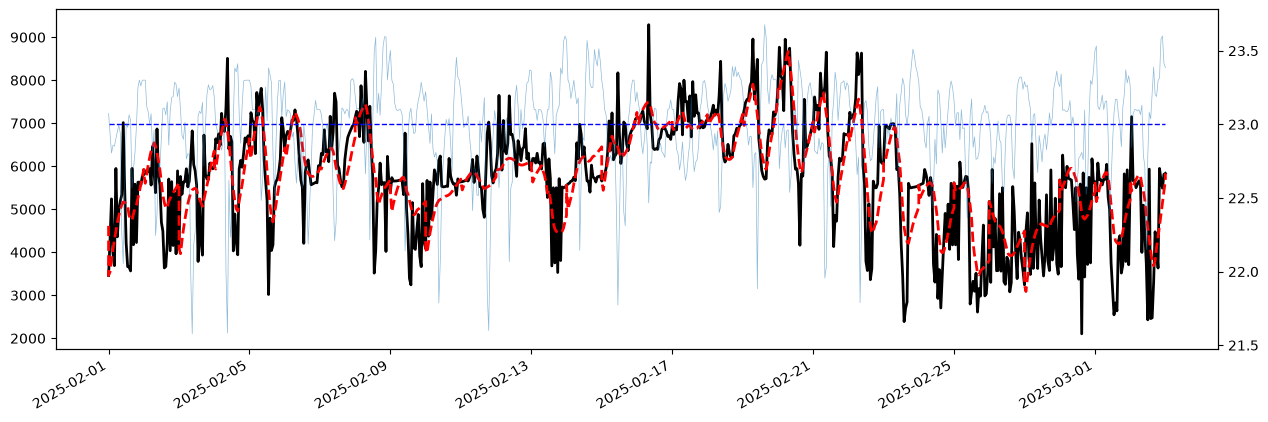

In [11]:
# PLOT
fig, ax = plt.subplots(figsize=(15,5))
axr = ax.twinx()
ds = "steps-post"
ds = "default"

t1 = datetime(2023,12,1)
t1 = datetime(2025,2,1)
t2 = t1 + timedelta(days=30)

dfbs_ = dfbs.loc[t1:t2]
dfbs_["y1_set"].plot(ax=axr, color="blue", label="y1_set", lw=1, ls="--", alpha=1, drawstyle=ds)
dfbs_["y1"].plot(ax=axr, color="tab:blue", label="y1_set", lw=0.5, alpha=0.5)

dfbs_["Phi_HC"].plot(ax=ax, color="k", label="Phi_HC", lw=2, alpha=1, drawstyle=ds)
dfbs_["Phi_HC_pred"].plot(ax=ax, color="red", label="Phi_HC_pred", lw=2, ls="--", alpha=1, drawstyle=ds)

In [12]:
from rctoolbox.evaluation.forecast_metrics import evaluate_forecast
p = evaluate_forecast(Phi_HC, Phi_HC_pred)
p["all_errors"]["t_start"] = pd.DatetimeIndex([row[0] for row in t_datetime])
p["all_errors"]["t_end"]   = pd.DatetimeIndex([row[-1] for row in t_datetime])

from rctoolbox.evaluation.forecast_metrics import organise_results_in_dataframe
summary_df = organise_results_in_dataframe(p['summary_statistics'])
summary_df

,mean,median,std,iqr
metric,,,,
CV(RMSE),16.66,15.06,7.93,"[9.47, 22.88]"
NMBE,1.83,1.90,7.06,"[-2.49, 4.98]"
MAE,608.06,612.64,203.32,"[446.32, 737.6]"
RE,5.52,4.22,4.78,"[2.22, 7.72]"
RMSE,798.96,797.40,242.75,"[612.63, 958.67]"
